# Info
## Objective
-   Develop a RNN model for time series forecasting using historical stock market data.
-   Apply deep learning techniques to predict future stock closing prices based on historical observations.
-   Gain practical experience in data preprocessing, sequence generation, model design, model training, and performance evaluation.
## Dataset description
-   Kaggle: Google Stock Data
-   Link: https://www.kaggle.com/datasets/varpit94/google-stock-data
-   File: GOOGL.csv
## Problem Statement
**Given historical stock prices from the previous 30 trading days, develop an RNN-based model to predict the closing stock price on the next trading day.**

# Import Libraries and Setup Environments

In [47]:
# Standard libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

# Keras for modeling RNN
from keras import Sequential
from keras.layers import Input, SimpleRNN, Dropout, Dense
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Time series specification
import scipy.stats as scs
from statsmodels.tsa.stattools import adfuller, kpss
from sklearn.preprocessing import MinMaxScaler

# Metrics
from sklearn.metrics import (
    mean_squared_error as mse, 
    mean_absolute_error as mae, 
    root_mean_squared_error as rmse, 
    mean_absolute_percentage_error as mape, 
    r2_score as r2)

# Others
import os
from pathlib import Path

In [48]:
gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow version:", tf.__version__)
print("GPU devices:", gpus)

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [49]:
# This will prodive VRAM on usage instead of giving all at once
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

In [50]:
import kagglehub
path = kagglehub.dataset_download(
    "varpit94/google-stock-data",
    force_download=True,
    output_dir="../data/raw" # This code cell is at notebook/, ".." will go back 1 step (to the repo's directory), then point to data/raw/
)

print("\nPath to dataset file(s): ", path)

100%|██████████| 101k/101k [00:00<00:00, 177kB/s]

Extracting files...

Path to dataset file(s):  ../data/raw


# Load the Dataset(s)

In [51]:
csv_path = Path(path) / "GOOGL.csv"
df = pd.read_csv(csv_path)
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date").sort_index()
print("Data is loaded successfully")

Data is loaded successfully


# Data Inspection

In [52]:
df.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2004-08-19,50.050049,52.082081,48.028027,50.220219,50.220219,44659096
2004-08-20,50.555557,54.594597,50.300301,54.209209,54.209209,22834343
2004-08-23,55.430431,56.796799,54.579578,54.754753,54.754753,18256126
2004-08-24,55.675674,55.855858,51.836838,52.487488,52.487488,15247337
2004-08-25,52.532532,54.054054,51.991993,53.053055,53.053055,9188602


In [53]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 4431 entries, 2004-08-19 to 2022-03-24
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       4431 non-null   float64
 1   High       4431 non-null   float64
 2   Low        4431 non-null   float64
 3   Close      4431 non-null   float64
 4   Adj Close  4431 non-null   float64
 5   Volume     4431 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 242.3 KB


In [54]:
df.isnull().sum()

Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

In [55]:
print(df.index.min(), "\tto\t", df.index.max())

2004-08-19 00:00:00 	to	 2022-03-24 00:00:00


In [56]:
# Compare Close and Adj Close
comparison = df[["Close", "Adj Close"]].copy()
comparison["Difference"] = comparison["Adj Close"] - comparison["Close"]

print("Different:", (comparison["Close"] != comparison["Adj Close"]).sum())

comparison.loc[comparison["Difference"] != 0].head()

Different: 0


,Close,Adj Close,Difference
Date,,,


It's good to see that Close and Adj Close are the same, though it may not practically be always true 

# Select Feature for Univariate Forecasting

In [57]:
FEATURES = ["Close"]
TARGET = "Close"

data = df[FEATURES].copy()

print("Selected features:", FEATURES)
print("Target:", TARGET)
print("Data shape:", data.shape)

data.head()

Selected features: ['Close']
Target: Close
Data shape: (4431, 1)


,Close
Date,
2004-08-19,50.220219
2004-08-20,54.209209
2004-08-23,54.754753
2004-08-24,52.487488
2004-08-25,53.053055


# Train-Test Split
Split the dataset (chronologically rather than randomly) into 3 parts.

Train : Val : Test = 70 : 15 : 15

In [58]:
n = len(data)
train_end = int(n * 0.70)
val_end = int(n * 0.85) # 70 + 15

splits = {
    "Train": data.iloc[:train_end],
    "Validation": data.iloc[train_end:val_end],
    "Test": data.iloc[val_end:]
}
summary = []
for split_name, df in splits.items():
    summary.append({
        "Split": split_name,
        "Rows": df.shape[0],
        "Start": df.index.min() if not df.empty else None,
        "End": df.index.max() if not df.empty else None,
    })

pd.DataFrame(summary).set_index("Split")


,Rows,Start,End
Split,,,
Train,3101,2004-08-19,2016-12-09
Validation,665,2016-12-12,2019-08-05
Test,665,2019-08-06,2022-03-24


# Data Normalization
-   Apply a suitable scaling technique, such as Min-Max scaling, to numerical features. 
-   Fit the scaler using the training data ONLY, then apply it to the validation and test data.

Here we choose MinMaxScaler. Apart from it will fit normalize on train set, for any value in val and test sets, if greater than max of test set, it will be scaled to a value > 1, which will not affect on the fact that the upper limit of a stock price is inf.

In [59]:
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(splits["Train"])
val_scaled = scaler.transform(splits["Validation"])
test_scaled = scaler.transform(splits["Test"])

print("\nTraining range after scaling:")
print("Min:", train_scaled.min())
print("Max:", train_scaled.max())


Training range after scaling:
Min: 0.0
Max: 1.0000000000000002


# Generate Sequences (Sliding Window)

In [60]:
LOOKBACK = 30

def create_sequences(data, lookback, horizon=1, target_length=1, target_idx=FEATURES.index(TARGET)):
    """
    Create sliding window for time series forecasting
    -   data: a pd.DataFrame or np.ndarray.
    -   lookback: The length of the window, aka how long will you lookback in the past data.
    -   horizon: The number of time steps from the window's last row to the target's first row.
    -   target_length: The number of continuous steps needed to be predicted. 
    -   target_idx: (Require FEATURES as a list of features that contains TARGET as a string) Index of the target in the list of features.
    """
    data = np.asarray(data)

    if data.ndim != 2:
        raise ValueError("data must have shape (n_samples, n_features)")
    if lookback < 1 or horizon < 1 or target_length < 1:
        raise ValueError("lookback, horizon, and target_length must be >= 1")
    if not 0 <= target_idx < data.shape[1]:
        raise ValueError("target_idx is out of range")

    X, y = [], []

    for i in range(len(data) - lookback - horizon - target_length + 2):
        i_end = i + lookback
        target_start = i_end + horizon - 1
        target_end = target_start + target_length

        seq_x = data[i:i_end, :]
        seq_y = data[target_start:target_end, target_idx]

        X.append(seq_x)
        y.append(seq_y)
    # Example: i=0, lookback=3, horizon=1, target_length=1:
    # Window: i_end=3 --> 0, 1, 2, count = lookback
    # Target: target_start=3, target_end=4
    return np.asarray(X), np.asarray(y)

In [61]:
X_train_seq, y_train_seq = create_sequences(train_scaled, LOOKBACK, target_idx=0)
X_val_seq, y_val_seq = create_sequences(val_scaled, LOOKBACK, target_idx=0)
X_test_seq, y_test_seq = create_sequences(test_scaled, LOOKBACK, target_idx=0)

print("X_train shape:\t", X_train_seq.shape, "\ty_train shape:\t", y_train_seq.shape)
print("X_val shape:\t", X_val_seq.shape, "\ty_val shape:\t", y_val_seq.shape)
print("X_test shape:\t", X_test_seq.shape, "\ty_test shape:\t", y_test_seq.shape)

X_train shape:	 (3071, 30, 1) 	y_train shape:	 (3071, 1)
X_val shape:	 (635, 30, 1) 	y_val shape:	 (635, 1)
X_test shape:	 (635, 30, 1) 	y_test shape:	 (635, 1)


# SimpleRNN Modeling
Note that we are currently on the path of Univariate Forecasting


In [62]:
simple_model = Sequential([
    Input(shape=(LOOKBACK, len(FEATURES))),
    SimpleRNN(64, activation="tanh"),
    Dropout(0.2),
    Dense(1)
])

simple_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_2 (SimpleRNN)        │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289 (16.75 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 0 (0.00 B)

In [63]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

In [64]:
simple_model.compile(optimizer="adam", loss='mse', metrics=['mae'])

history_simple = simple_model.fit(
    X_train_seq, y_train_seq,
    batch_size=64,
    epochs=100,
    validation_data=(X_val_seq, y_val_seq),
    callbacks=[early_stopping, reduce_lr],
    shuffle=False,
    verbose=1
)

Epoch 1/100


I0000 00:00:1793314377.551186   33516 dot_merger.cc:481] Merging Dots in computation: sequential_2_1_simple_rnn_2_1_while_body_15430_grad_15661_const_0__.18.clone.clone.clone.clone.clone


45/48 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0140 - mae: 0.0885

I0000 00:00:1793314379.051484   33512 dot_merger.cc:481] Merging Dots in computation: sequential_2_1_simple_rnn_2_1_while_body_15430_grad_15661_const_0__.18.clone.clone.clone.clone.clone


48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 0.0149 - mae: 0.0910 - val_loss: 0.1475 - val_mae: 0.3464 - learning_rate: 0.0010
Epoch 2/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0162 - mae: 0.0965 - val_loss: 0.0666 - val_mae: 0.2293 - learning_rate: 0.0010
Epoch 3/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0080 - mae: 0.0726 - val_loss: 0.0179 - val_mae: 0.1191 - learning_rate: 0.0010
Epoch 4/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0032 - mae: 0.0435 - val_loss: 0.0131 - val_mae: 0.1013 - learning_rate: 0.0010
Epoch 5/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0024 - mae: 0.0358 - val_loss: 0.0059 - val_mae: 0.0641 - learning_rate: 0.0010
Epoch 6/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0018 - mae: 0.0307 - val_loss: 0.0057 - val_mae: 0.0638 - learning_rate: 0.0010
Epoch 7/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0017 - mae: 0.0280 - val_loss: 0.0054 - val_mae: 0.0621 - learning_rate: 0.0010
Epoch 8/100
48/48 

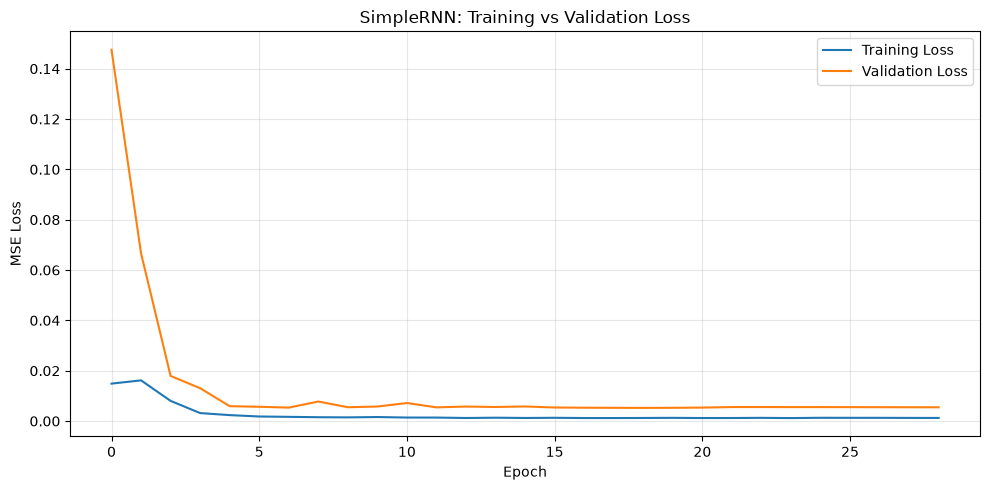

In [65]:
plt.figure(figsize=(10, 5))

plt.plot(history_simple.history["loss"], label="Training Loss")
plt.plot(history_simple.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("SimpleRNN: Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Predicting and Inverse Scaling

In [66]:
y_pred_scaled = simple_model.predict(X_test_seq, verbose=0)

y_pred = scaler.inverse_transform(y_pred_scaled)
y_test = scaler.inverse_transform(y_test_seq)

print("Predictions shape:", y_pred.shape)
print("Actual values shape:", y_test.shape)

print("\nFirst 5 predictions vs actual values:")
comparison = pd.DataFrame({
    "Actual Close": y_test.flatten(),
    "Predicted Close": y_pred.flatten(),
    "Difference": (y_test.flatten() - y_pred.flatten())
})

comparison.head(10)

Predictions shape: (635, 1)
Actual values shape: (635, 1)

First 5 predictions vs actual values:


,Actual Close,Predicted Close,Difference
0,1232.650024,1149.205322,83.444702
1,1238.750000,1152.339966,86.410034
2,1229.839966,1155.978882,73.861084
3,1234.689941,1150.681763,84.008178
4,1218.329956,1145.927612,72.402344
5,1245.939941,1147.410645,98.529296
6,1242.290039,1145.159058,97.130981
7,1225.949951,1148.541504,77.408447
8,1221.140015,1149.641602,71.498413
9,1206.000000,1143.115967,62.884033


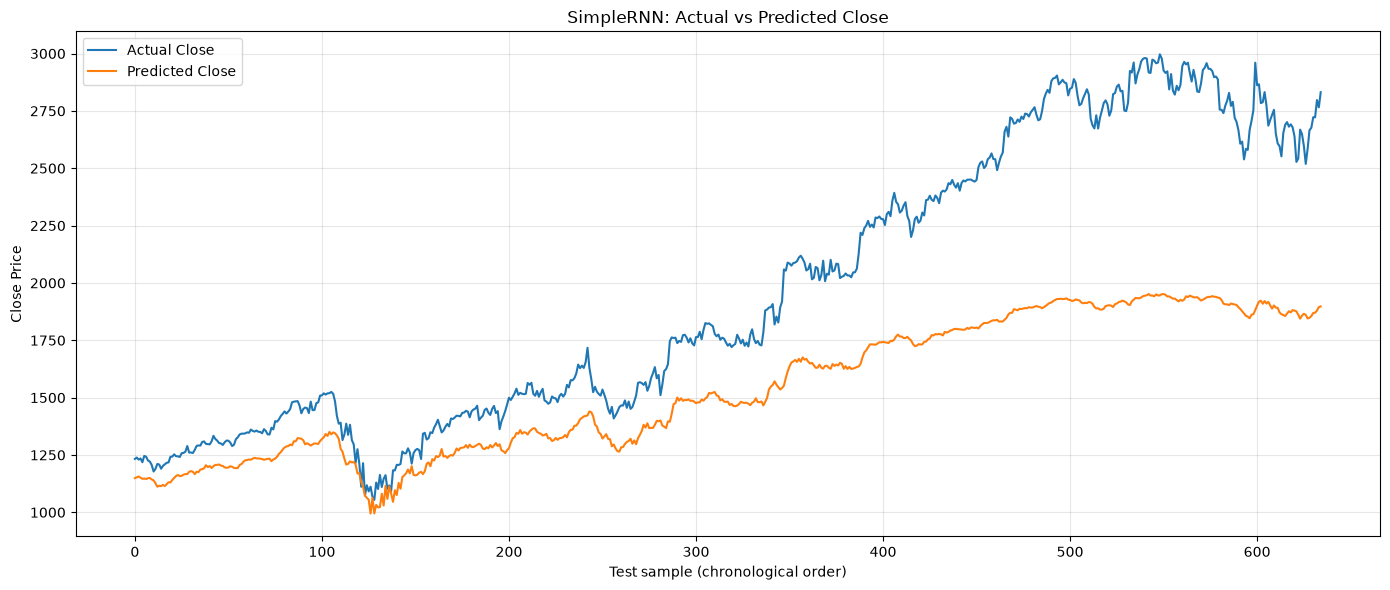

In [67]:
plt.figure(figsize=(14, 6))

plt.plot(y_test.flatten(), label="Actual Close")
plt.plot(y_pred.flatten(), label="Predicted Close")

plt.xlabel("Test sample (chronological order)")
plt.ylabel("Close Price")
plt.title("SimpleRNN: Actual vs Predicted Close")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Metrics

In [68]:
y_true = y_test.flatten()
y_pred_flat = y_pred.flatten()

metrics = {
    "MAE": mae(y_true, y_pred_flat),
    "MSE": mse(y_true, y_pred_flat),
    "RMSE": rmse(y_true, y_pred_flat),
    "R²": r2(y_true, y_pred_flat)
}

metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Value"]
)

display(metrics_df)

,Metric,Value
0,MAE,427.539900
1,MSE,287010.839400
2,RMSE,535.733926
3,R²,0.225538


In [69]:
print(comparison["Difference"].describe())
print()
print(
    "Maximum absolute error:",
    comparison["Difference"].abs().max()
)
print()
print(
    "95th percentile absolute error:",
    comparison["Difference"].abs().quantile(0.95)
)

count     635.000000
mean      427.475573
std       323.171697
min       -20.063110
25%       148.102906
50%       281.685424
75%       737.766480
max      1078.324463
Name: Difference, dtype: float64

Maximum absolute error: 1078.324462890625

95th percentile absolute error: 971.0422121093749


Explanation:
-   mean > 0: Prediction is practically higher than y_true
-   Q1, Q2 (50%, aka median), Q3 > 0: 25%, 50%, and 75% of the differences are less than the given values. All are positive values, which means differences tend to bias towards the prediction side.
-   min < 0: There is a prediction lower than y_true
-   max > 0: There is a prediction higher than y_true